# AI Assignment

**AI used**: ChatGPT

**Prompt:** I have a CSV file called "card_transdata.csv". 
Load me a code that imports pandas as pd, seaborn as sns, matplotlib.pyplot as plt, plotly.express as px, and then import train_test_split from sklearn.model_selection, StandardScaler from sklearn.preprocessing, KNeighborsClassifier from sklearn.neighbors, and confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score from sklearn.metrics. 
Then read in the file as transaction_data_raw and give me the first couple of lines of that file.

In [ ]:
# Import libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# Import machine learning tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [5]:
# Read in the CSV file
transaction_data_raw = pd.read_csv("card_transdata.csv")

# Display the first 5 rows
transaction_data_raw.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


**Prompt:** Can you now generate code that checks for missing values in transaction_data_raw? Then, can you drop the rows with null values, then display the first few rows of the cleaned dataframe?can you give me code that visualize the class distribution using countplot? Make the title be 'Fraud Class Distribution' and x be fraud

In [7]:
# Check the number of missing values in each column
transaction_data_raw.isnull().sum()

# Drop rows with missing values
transaction_data_clean = transaction_data_raw.dropna()

# Display the first 5 rows of the cleaned DataFrame
transaction_data_clean.head()

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0
5,5.586408,13.261073,0.064768,1.0,0.0,0.0,0.0,0
6,3.724019,0.956838,0.278465,1.0,0.0,0.0,1.0,0


**Prompt:** Can you give me code that visualize the class distribution using countplot? Make the title be 'Fraud Class Distribution' and x be fraud

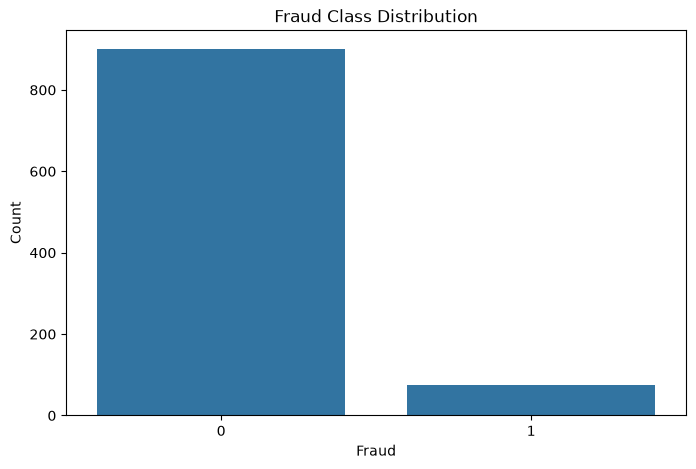

In [8]:
# Visualize class distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=transaction_data_clean, x='fraud')

# Add title and labels
plt.title('Fraud Class Distribution')
plt.xlabel('Fraud')
plt.ylabel('Count')

plt.show()

**Prompt:** Do the same thing, but with x='used_pin_number' and title being 'Used Pin Distribution'

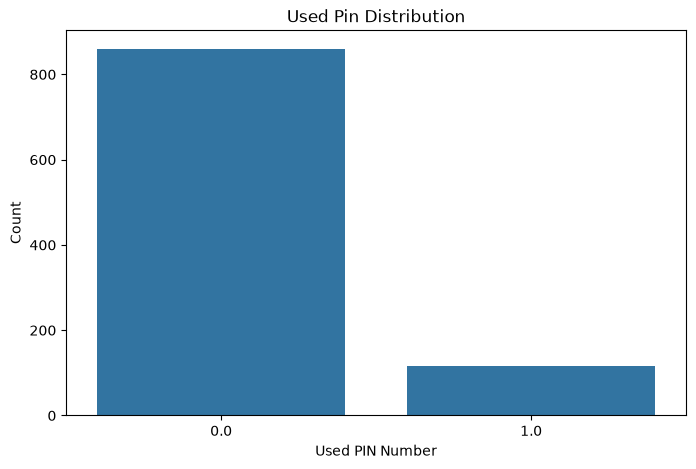

In [9]:
# Visualize used PIN distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=transaction_data_clean, x='used_pin_number')

# Add title and labels
plt.title('Used Pin Distribution')
plt.xlabel('Used PIN Number')
plt.ylabel('Count')

plt.show()

**Prompt:** Same thing but with x='repeat_retailer' and title 'Repeat Retailer Distribution'

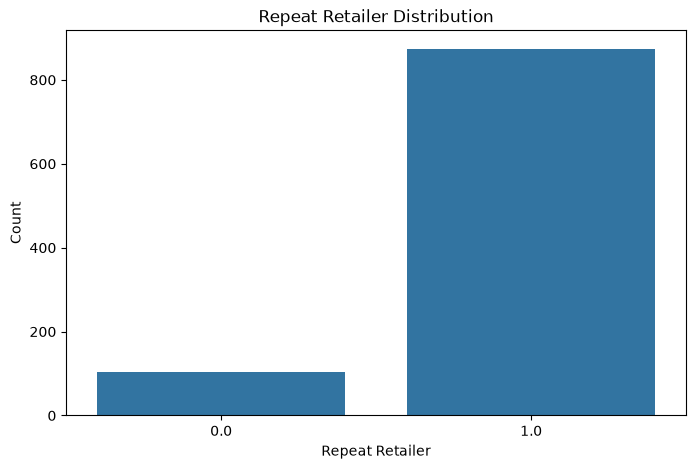

In [10]:
# Visualize repeat retailer distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=transaction_data_clean, x='repeat_retailer')

# Add title and labels
plt.title('Repeat Retailer Distribution')
plt.xlabel('Repeat Retailer')
plt.ylabel('Count')

plt.show()

**Prompt:** Same thing x='online_order', title 'Online Orders'

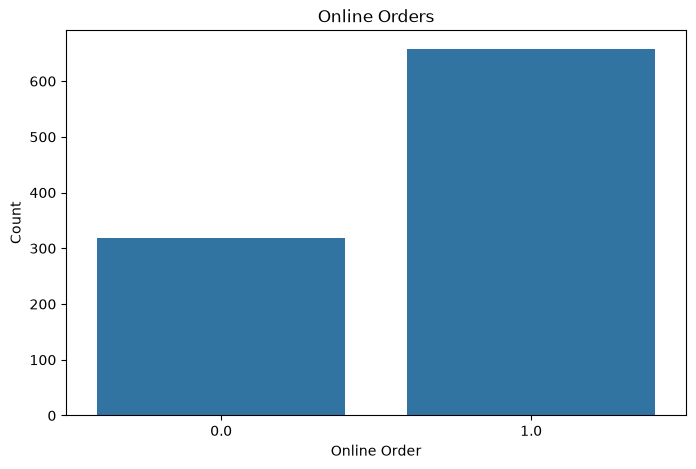

In [11]:
# Visualize online order distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=transaction_data_clean, x='online_order')

# Add title and labels
plt.title('Online Orders')
plt.xlabel('Online Order')
plt.ylabel('Count')

plt.show()

**Prompt:** Create a histplot with bins=30 to see distribution of 'ratio_to_median_purchase_price' with title 'Ratio to Median Purchase Price Distribution'

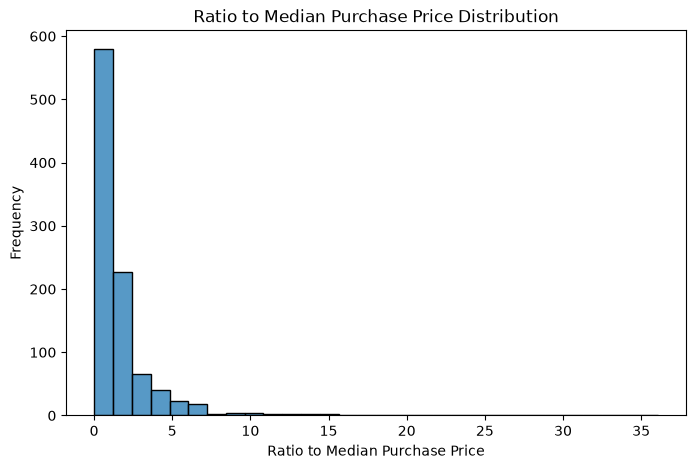

In [12]:
# Visualize ratio to median purchase price distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=transaction_data_clean, x='ratio_to_median_purchase_price', bins=30)

# Add title and labels
plt.title('Ratio to Median Purchase Price Distribution')
plt.xlabel('Ratio to Median Purchase Price')
plt.ylabel('Frequency')

plt.show()

**Prompt:** Same but with 'distance_from_home'

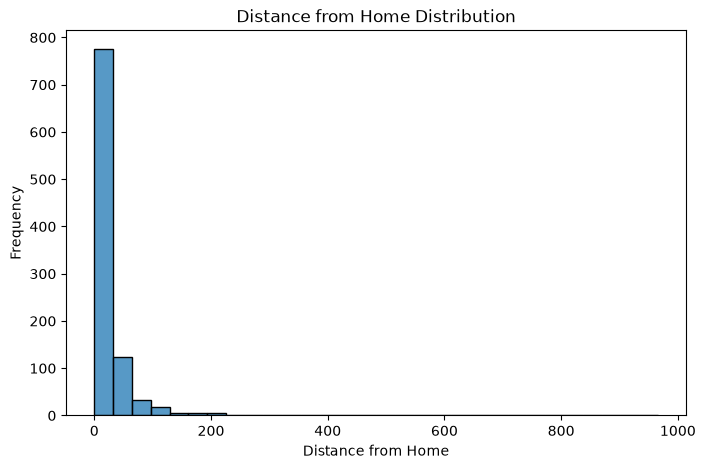

In [13]:
# Visualize distance from home distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=transaction_data_clean, x='distance_from_home', bins=30)

# Add title and labels
plt.title('Distance from Home Distribution')
plt.xlabel('Distance from Home')
plt.ylabel('Frequency')

plt.show()

**Prompt:** create a countplot with x='used_pin_number', hue='fraud', and using green and red to distinguish them. have a legend that has labels 'Non-Fraudulent' and 'Fraudulent'

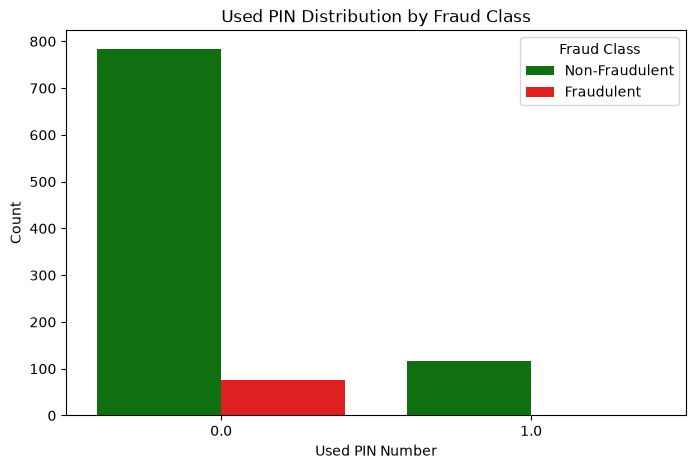

In [14]:
# Visualize used PIN distribution by fraud class
plt.figure(figsize=(8, 5))
sns.countplot(
    data=transaction_data_clean,
    x='used_pin_number',
    hue='fraud',
    palette={0: 'green', 1: 'red'}
)

# Add title and labels
plt.title('Used PIN Distribution by Fraud Class')
plt.xlabel('Used PIN Number')
plt.ylabel('Count')

# Customize legend
plt.legend(title='Fraud Class', labels=['Non-Fraudulent', 'Fraudulent'])

plt.show()

**Prompt:** Create a percentage plot to show the percentage of fraudulent transactions when a PIN was used or not. use group by 'used_pin_number', make it a bar plot with the colours still being green and red, still including a legend. Let it be stacked. 

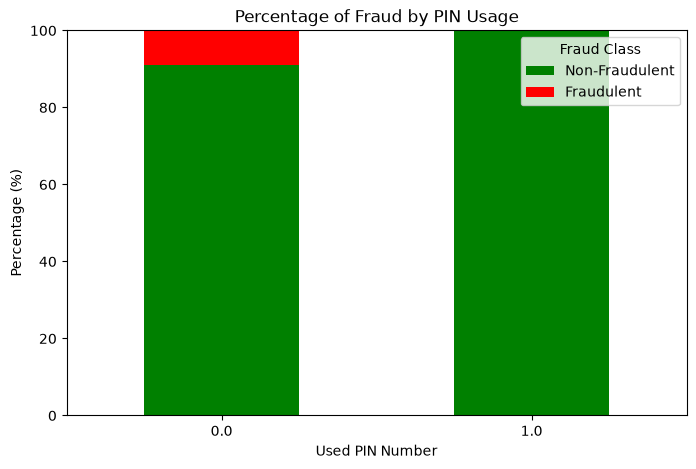

In [16]:
# Calculate percentage of fraud by PIN usage
pin_fraud_percentage = (
    transaction_data_clean.groupby('used_pin_number')['fraud']
    .value_counts(normalize=True)
    .mul(100)
    .unstack()
)

# Create stacked percentage bar plot
pin_fraud_percentage.plot(
    kind='bar',
    stacked=True,
    color=['green', 'red'],
    figsize=(8, 5)
)

# Add title and labels
plt.title('Percentage of Fraud by PIN Usage')
plt.xlabel('Used PIN Number')
plt.ylabel('Percentage (%)')

# Customize legend
plt.legend(
    title='Fraud Class',
    labels=['Non-Fraudulent', 'Fraudulent']
)

plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.show()

**Prompt:** Create a count plot to show the number of transactions that were fraudulent vs non-fraudulent when a chip was used or not. same criterias as before with colours and legend, x='used_chip'

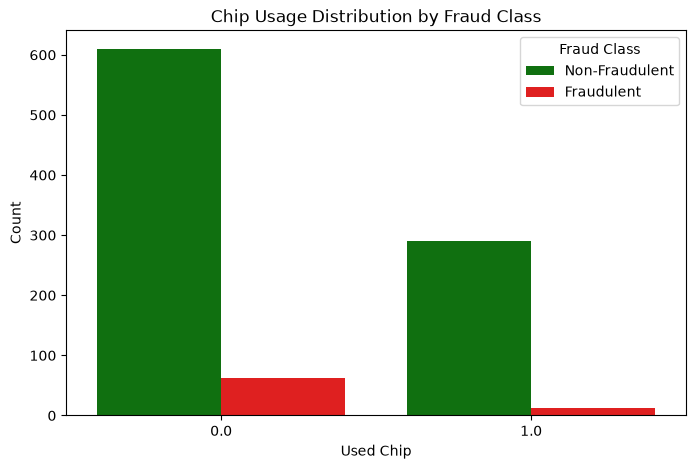

In [17]:
# Visualize chip usage distribution by fraud class
plt.figure(figsize=(8, 5))
sns.countplot(
    data=transaction_data_clean,
    x='used_chip',
    hue='fraud',
    palette={0: 'green', 1: 'red'}
)

# Add title and labels
plt.title('Chip Usage Distribution by Fraud Class')
plt.xlabel('Used Chip')
plt.ylabel('Count')

# Customize legend
plt.legend(
    title='Fraud Class',
    labels=['Non-Fraudulent', 'Fraudulent']
)

plt.show()

**Prompt:** Create a percentage plot to show the percentage of fraudulent transactions when a chip was used or not. make sure it's stacked. group by 'used_chip

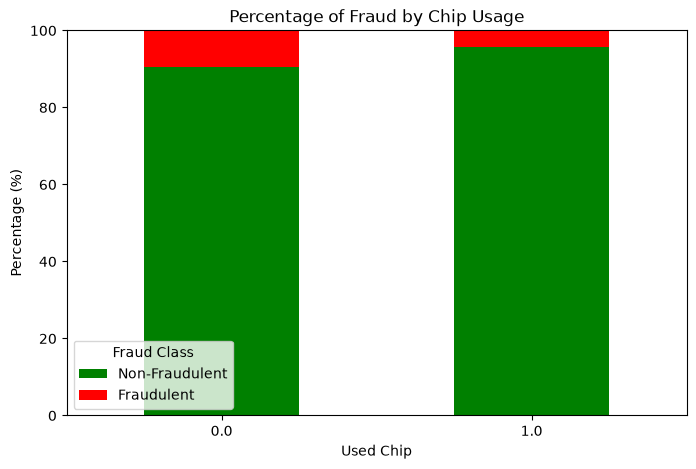

In [18]:
# Calculate percentage of fraud by chip usage
chip_fraud_percentage = (
    transaction_data_clean.groupby('used_chip')['fraud']
    .value_counts(normalize=True)
    .mul(100)
    .unstack()
)

# Create stacked percentage bar plot
chip_fraud_percentage.plot(
    kind='bar',
    stacked=True,
    color=['green', 'red'],
    figsize=(8, 5)
)

# Add title and labels
plt.title('Percentage of Fraud by Chip Usage')
plt.xlabel('Used Chip')
plt.ylabel('Percentage (%)')

# Customize legend
plt.legend(
    title='Fraud Class',
    labels=['Non-Fraudulent', 'Fraudulent']
)

plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.show()

**Prompt:** Create a count plot with x=online_order with same criteras as before

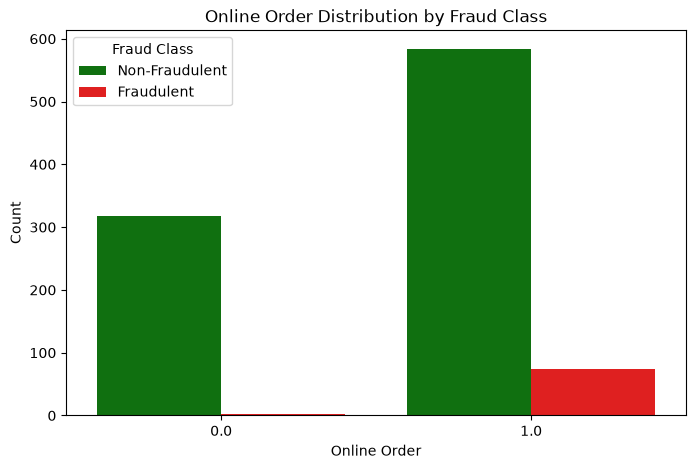

In [19]:
# Visualize online order distribution by fraud class
plt.figure(figsize=(8, 5))
sns.countplot(
    data=transaction_data_clean,
    x='online_order',
    hue='fraud',
    palette={0: 'green', 1: 'red'}
)

# Add title and labels
plt.title('Online Order Distribution by Fraud Class')
plt.xlabel('Online Order')
plt.ylabel('Count')

# Customize legend
plt.legend(
    title='Fraud Class',
    labels=['Non-Fraudulent', 'Fraudulent']
)

plt.show()

**Prompt:** Create a percentage plot to show the percentage of fraudulent transactions when it was an online order or not

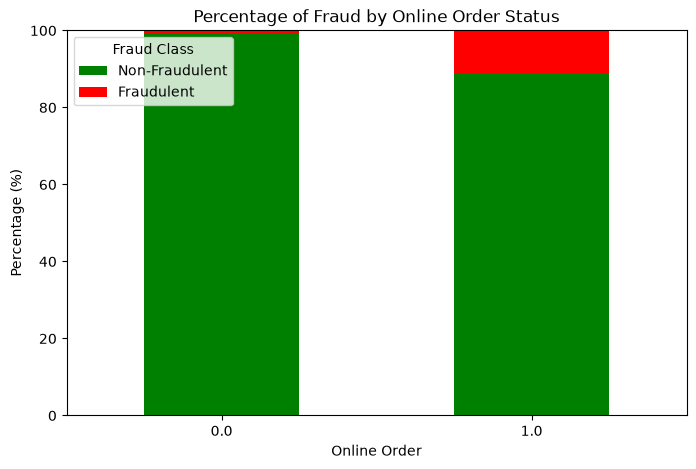

In [21]:
# Calculate percentage of fraud by online order status
online_fraud_percentage = (
    transaction_data_clean.groupby('online_order')['fraud']
    .value_counts(normalize=True)
    .mul(100)
    .unstack()
)

# Create stacked percentage bar plot
online_fraud_percentage.plot(
    kind='bar',
    stacked=True,
    color=['green', 'red'],
    figsize=(8, 5)
)

# Add title and labels
plt.title('Percentage of Fraud by Online Order Status')
plt.xlabel('Online Order')
plt.ylabel('Percentage (%)')

# Customize legend
plt.legend(
    title='Fraud Class',
    labels=['Non-Fraudulent', 'Fraudulent']
)

plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.show()

**Prompt:** Create a scatter plot to show the breakdown of fraudulent and non-fraudulent transactions for distance_from_last_transaction vs ratio_to_median_purchase_price

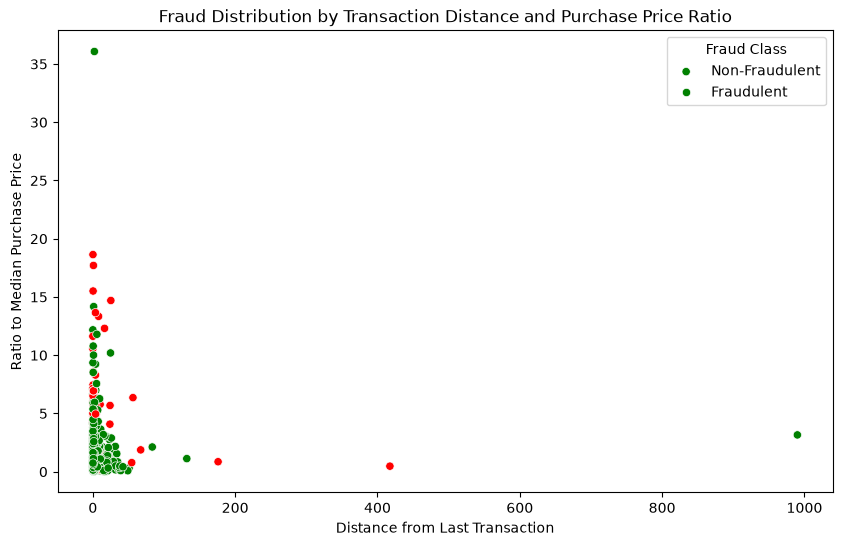

In [22]:
# Visualize fraud distribution by transaction distance and purchase price ratio
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=transaction_data_clean,
    x='distance_from_last_transaction',
    y='ratio_to_median_purchase_price',
    hue='fraud',
    palette={0: 'green', 1: 'red'}
)

# Add title and labels
plt.title('Fraud Distribution by Transaction Distance and Purchase Price Ratio')
plt.xlabel('Distance from Last Transaction')
plt.ylabel('Ratio to Median Purchase Price')

# Customize legend
plt.legend(
    title='Fraud Class',
    labels=['Non-Fraudulent', 'Fraudulent']
)

plt.show()

**Prompt:** Create a scatter plot to show the breakdown of fraudulent and non-fraudulent transactions. x = 'distance_from_home', y='ratio_to_median_purchase_price'

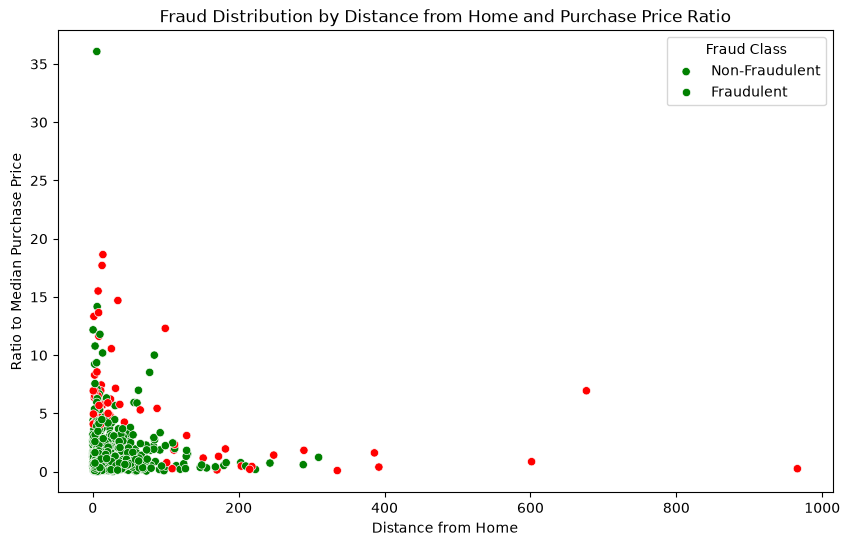

In [24]:
# Visualize fraud distribution by distance from home and purchase price ratio
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=transaction_data_clean,
    x='distance_from_home',
    y='ratio_to_median_purchase_price',
    hue='fraud',
    palette={0: 'green', 1: 'red'}
)

# Add title and labels
plt.title('Fraud Distribution by Distance from Home and Purchase Price Ratio')
plt.xlabel('Distance from Home')
plt.ylabel('Ratio to Median Purchase Price')

# Customize legend
plt.legend(
    title='Fraud Class',
    labels=['Non-Fraudulent', 'Fraudulent']
)